# 02 · Strata profile of the scored tracts

Who lives in the 9,794 scored tracts, how vulnerable and hazard-exposed are they, and how complete are the strata? Everything is read from the committed `analysis_outputs/` tables, so this runs without the raw zips.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "analysis_outputs").exists())
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})

REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))

# one table: Overture aggregates + ACS + strata, one row per scored tract (built by the earlier notebooks)
df = pd.read_parquet(OUT / "tract_analysis_table.parquet")
df["land_km2"] = df.ALAND / 1e6

def box_by_region(ax, col, data=None, log=False, title="", ylabel=None):
    """Box plot of one column for each region (log10 if log=True), n shown under each box."""
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    """Number of values outside the 1.5 x IQR fences."""
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    """Annotated heatmap of a DataFrame."""
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. How big is each region, and who lives there?

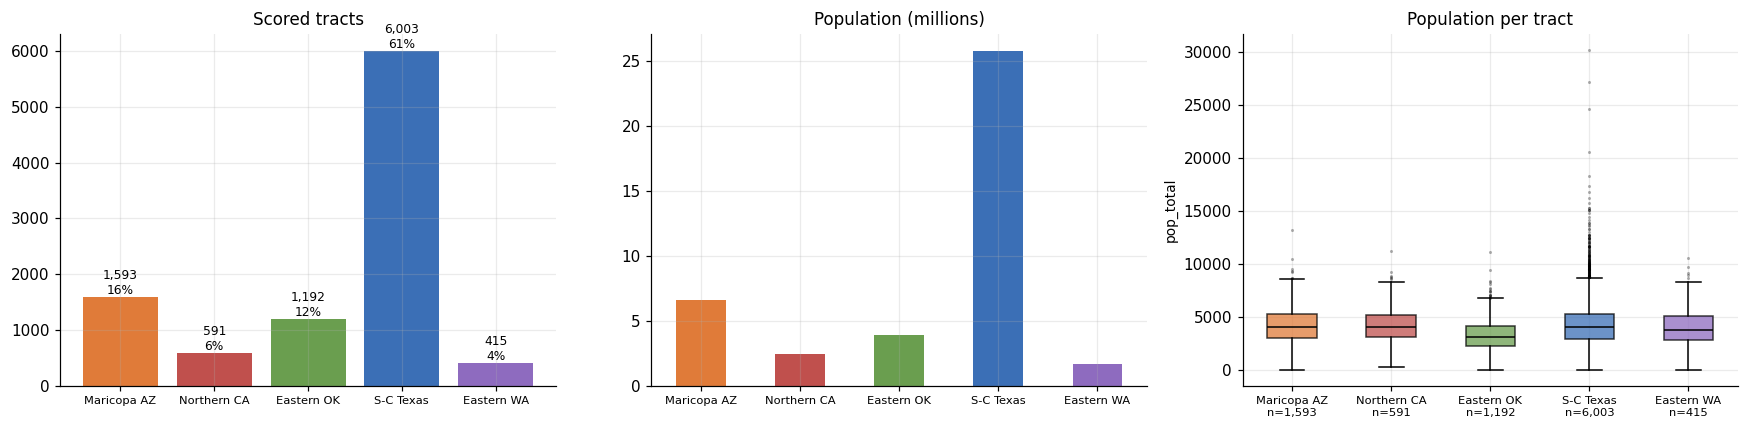

Texas share of tracts: 61.3% | of population: 63.7%


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
n = df.region.value_counts().reindex(REG)
ax[0].bar([NAME[r] for r in REG], n, color=[COL[r] for r in REG]); ax[0].set_title("Scored tracts")
for i, v in enumerate(n): ax[0].text(i, v, f"{v:,}\n{v / len(df):.0%}", ha="center", va="bottom", fontsize=8)
(df.groupby("region").pop_total.sum().reindex(REG) / 1e6).plot.bar(ax=ax[1], color=[COL[r] for r in REG], rot=0); ax[1].set_title("Population (millions)"); ax[1].set_xlabel("")
box_by_region(ax[2], "pop_total", title="Population per tract")
for a in ax[:2]: a.set_xticklabels([NAME[r] for r in REG], fontsize=7.5, rotation=0)
plt.tight_layout(); plt.show()
print(f"Texas share of tracts: {n['south-central-tx'] / len(df):.1%} | of population: {df[df.region == 'south-central-tx'].pop_total.sum() / df.pop_total.sum():.1%}")

**Takeaway:** Texas is about 61% of the tracts and 64% of the people, so any pooled statistic mostly describes Texas.

## 2. Urban / rural, RUCA and tribal composition

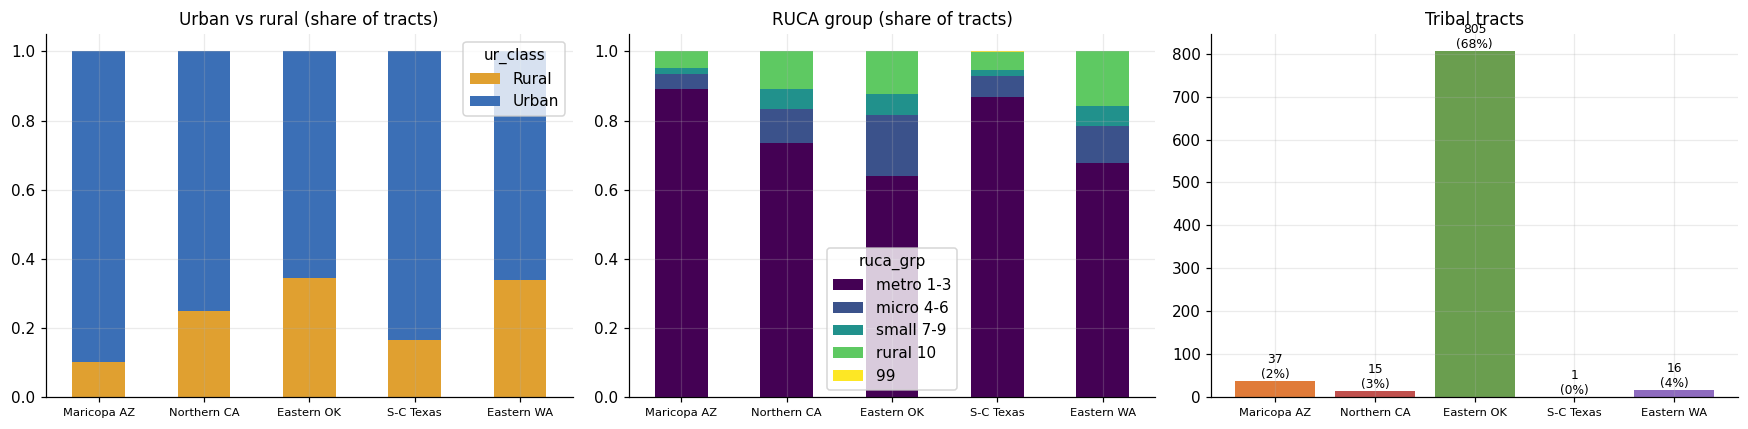

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
pd.crosstab(df.region, df.ur_class, normalize="index").reindex(REG).plot.bar(stacked=True, ax=ax[0], rot=0, color=["#e0a030", "#3b6fb6"]); ax[0].set_title("Urban vs rural (share of tracts)")
pd.crosstab(df.region, df.ruca_grp, normalize="index").reindex(REG).plot.bar(stacked=True, ax=ax[1], rot=0, colormap="viridis"); ax[1].set_title("RUCA group (share of tracts)")
t = df.groupby("region").tribal.agg(["sum", "mean"]).reindex(REG); ax[2].bar([NAME[r] for r in REG], t["sum"], color=[COL[r] for r in REG]); ax[2].set_title("Tribal tracts")
for i, (s, m) in enumerate(zip(t["sum"], t["mean"])): ax[2].text(i, s, f"{int(s)}\n({m:.0%})", ha="center", va="bottom", fontsize=8)
for a in ax: a.set_xticklabels([NAME[r] for r in REG], fontsize=7.5, rotation=0); a.set_xlabel("")
plt.tight_layout(); plt.show()

**Takeaway:** 805 of the 874 tribal tracts are in Eastern Oklahoma (67% of that region), so tribal comparisons are mostly Oklahoma comparisons. Oklahoma and Washington are the most rural regions.

## 3. Shape of the key variables

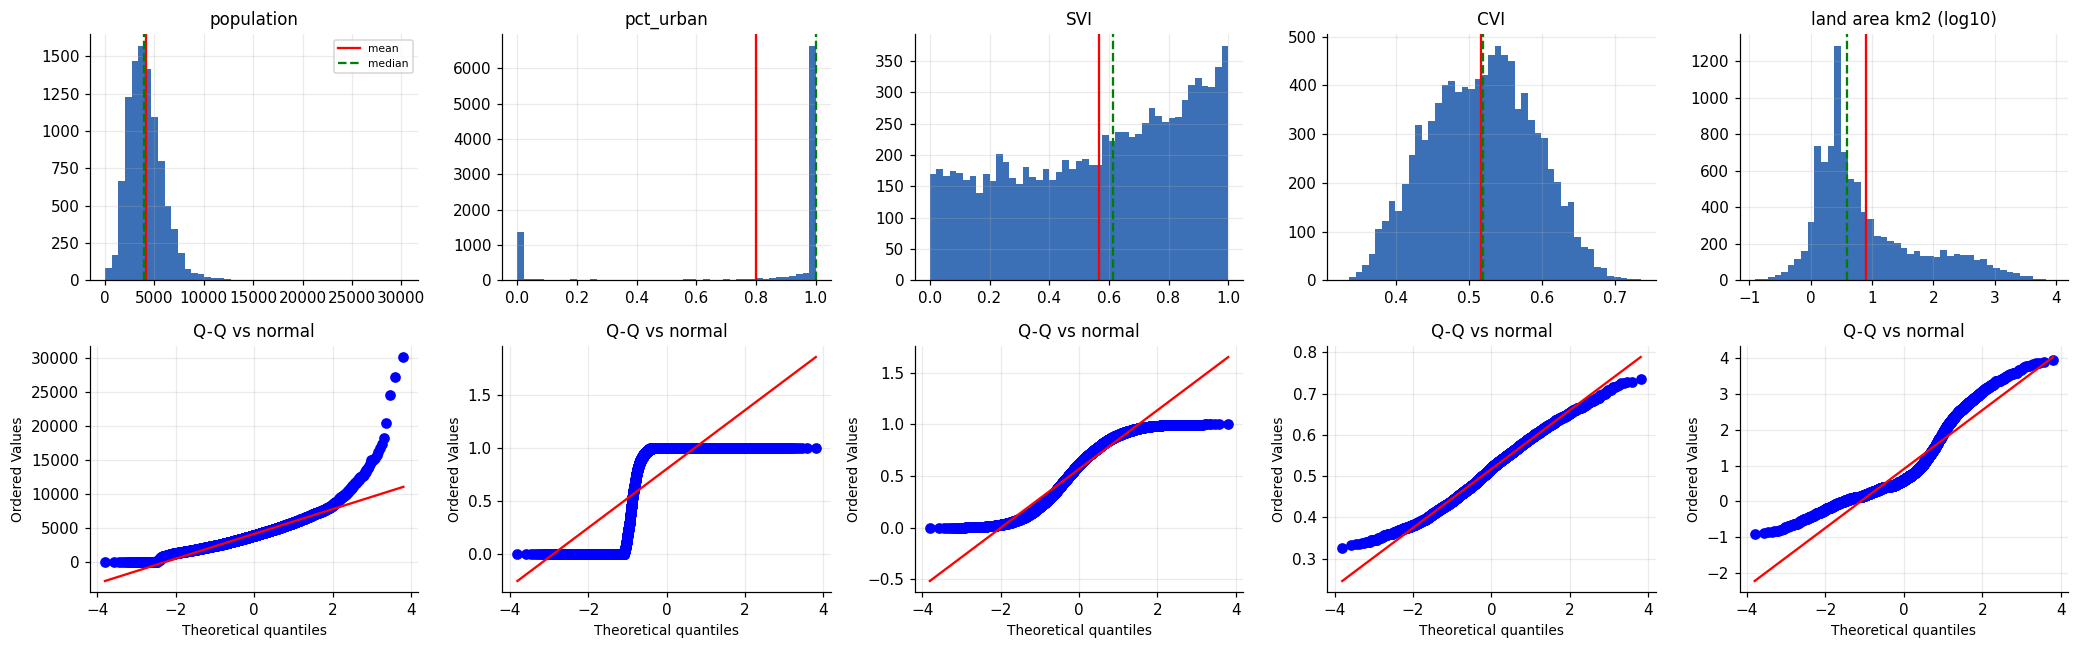

     variable    mean  median      sd  skew  excess kurtosis  IQR outliers
   population 4127.77 3901.00 1902.06  1.68            10.57           207
    pct_urban    0.80    1.00    0.37 -1.54             0.55          2060
          SVI    0.57    0.61    0.29 -0.30            -1.15             0
          CVI    0.52    0.52    0.07  0.00            -0.60             3
land area km2    0.90    0.60    0.87  1.08             0.42           381


In [4]:
V = {"pop_total": "population", "pct_urban": "pct_urban", "svi_overall": "SVI", "cvi_overall": "CVI", "land_km2": "land area km2"}
fig, ax = plt.subplots(2, 5, figsize=(19, 6)); rows = []
for j, (c, nm) in enumerate(V.items()):
    x = df[c].dropna(); x = np.log10(x[x > 0]) if c == "land_km2" else x
    ax[0, j].hist(x, bins=45, color="#3b6fb6"); ax[0, j].axvline(x.mean(), color="r", label="mean"); ax[0, j].axvline(x.median(), color="g", ls="--", label="median")
    ax[0, j].set_title(nm + (" (log10)" if c == "land_km2" else "")); stats.probplot(x, plot=ax[1, j]); ax[1, j].set_title("Q-Q vs normal")
    rows.append((nm, x.mean(), x.median(), x.std(), stats.skew(x), stats.kurtosis(x), n_outliers(x)))
ax[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()
print(pd.DataFrame(rows, columns=["variable", "mean", "median", "sd", "skew", "excess kurtosis", "IQR outliers"]).round(2).to_string(index=False))

**Takeaway:** population is right-skewed with a heavy tail (skew 1.7, 207 outliers). `pct_urban` is U-shaped (most tracts are exactly 0 or 1), so its mean and median mislead. SVI is flat and bounded, and CVI is narrow (sd 0.07).

## 4. Vulnerability and hazard exposure by region

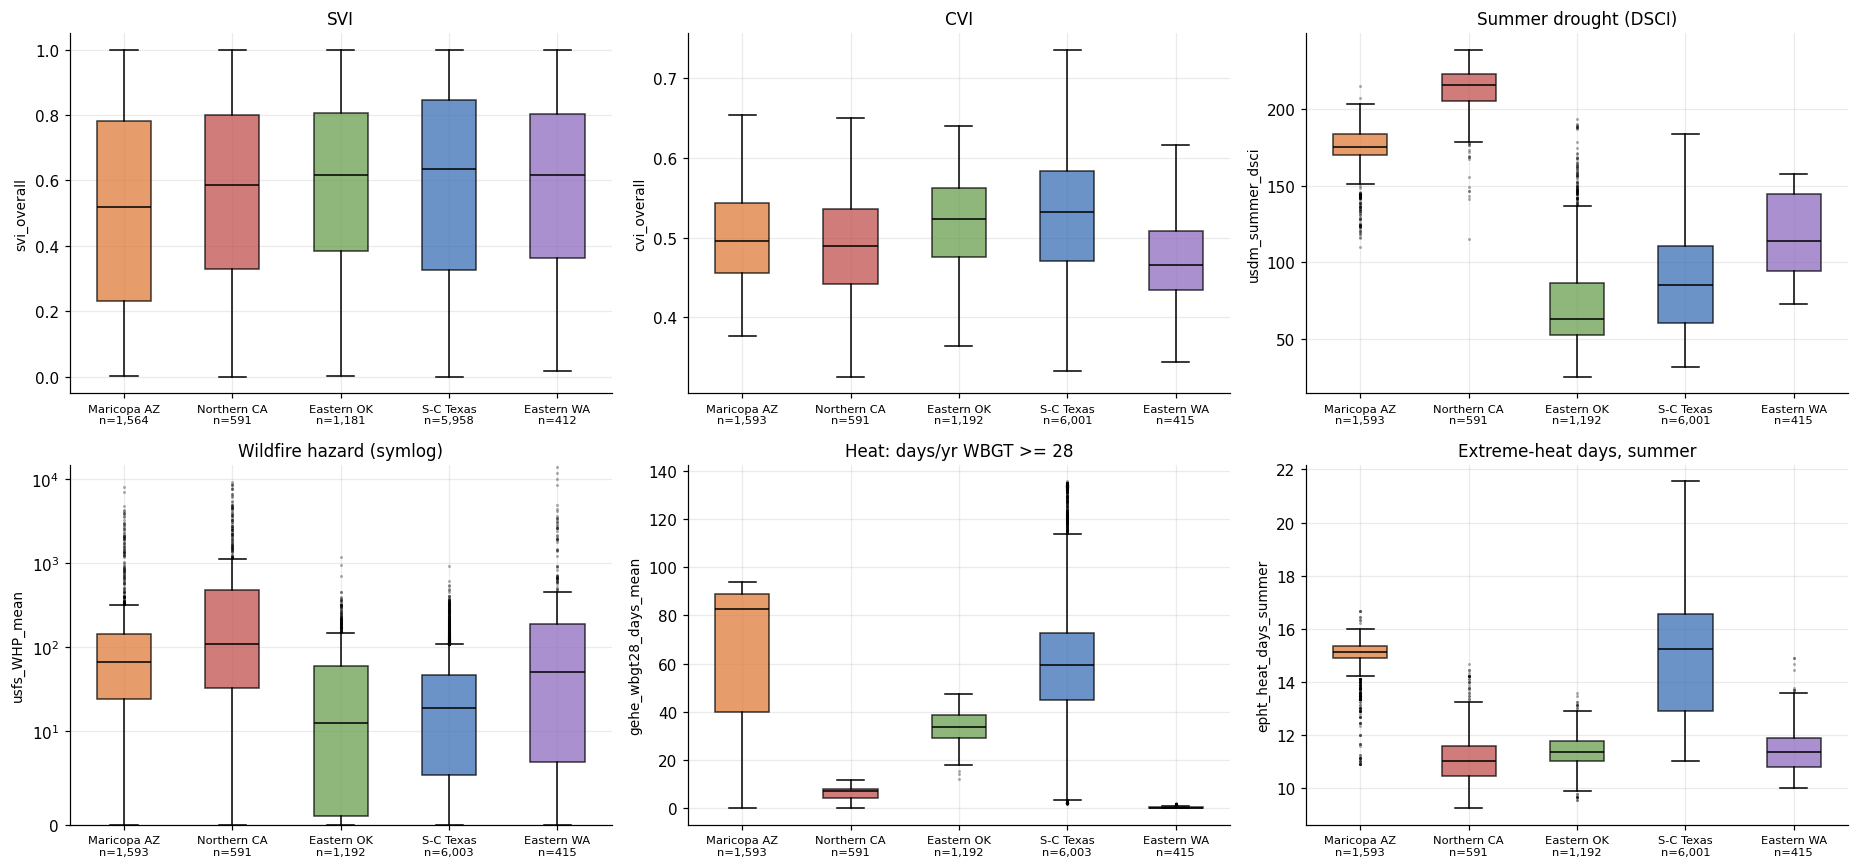

                  usdm_summer_dsci  usfs_WHP_mean  gehe_wbgt28_days_mean
region                                                                  
maricopa-az                  175.6           66.1                   82.6
northern-ca                  216.0          108.0                    7.3
eastern-ok                    63.3           12.6                   33.8
south-central-tx              85.2           18.8                   59.6
eastern-wa                   114.2           50.5                    0.1


In [5]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, (c, t) in zip(ax.ravel(), [("svi_overall", "SVI"), ("cvi_overall", "CVI"), ("usdm_summer_dsci", "Summer drought (DSCI)"),
                                  ("usfs_WHP_mean", "Wildfire hazard (symlog)"), ("gehe_wbgt28_days_mean", "Heat: days/yr WBGT >= 28"), ("epht_heat_days_summer", "Extreme-heat days, summer")]):
    box_by_region(a, c, title=t)
ax[1, 0].set_yscale("symlog", linthresh=10); ax[1, 0].set_ylim(bottom=0); plt.tight_layout(); plt.show()
print(df.groupby("region")[["usdm_summer_dsci", "usfs_WHP_mean", "gehe_wbgt28_days_mean"]].median().reindex(REG).round(1).to_string())

**Takeaway:** hazards are regional: Maricopa has the most extreme-heat days, Northern California the highest drought and wildfire hazard, Eastern Washington almost no extreme heat. SVI varies much less across regions than the hazards do, so region is partly a stand-in for hazard exposure.

## 5. Do the regions differ in SVI? Intervals and tests

ANOVA F = 18.8 (p = 2.2e-15) | Kruskal-Wallis H = 68.7 (p = 4.3e-14) | eta-squared = 0.008


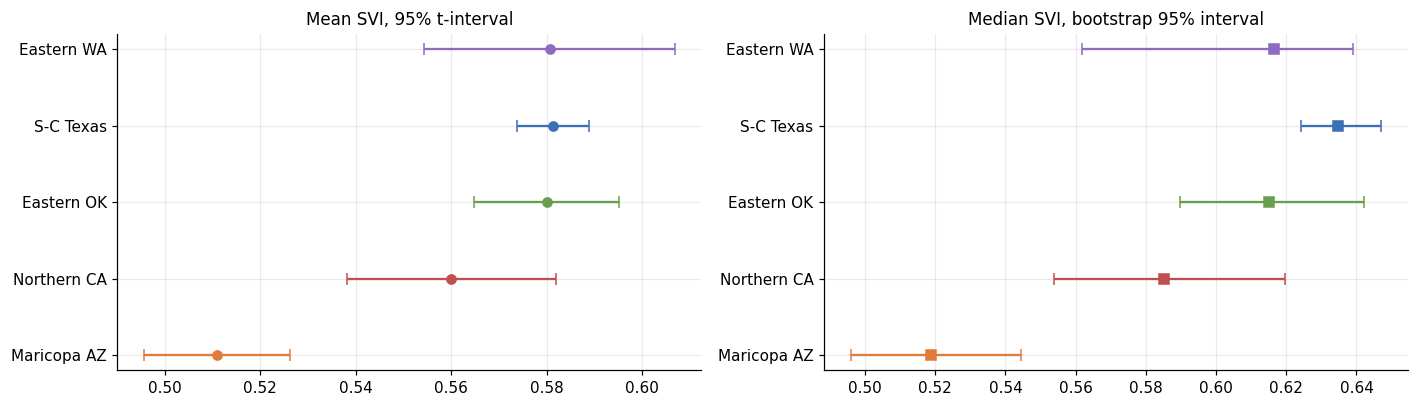

In [6]:
g = [df.loc[df.region == r, "svi_overall"].dropna() for r in REG]; allv = pd.concat(g)
F, pF = stats.f_oneway(*g); H, pH = stats.kruskal(*g); eta2 = sum(len(x) * (x.mean() - allv.mean()) ** 2 for x in g) / ((allv - allv.mean()) ** 2).sum()
print(f"ANOVA F = {F:.1f} (p = {pF:.1e}) | Kruskal-Wallis H = {H:.1f} (p = {pH:.1e}) | eta-squared = {eta2:.3f}")
rng = np.random.default_rng(42)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for i, (r, x) in enumerate(zip(REG, g)):
    h = stats.t.ppf(.975, len(x) - 1) * x.sem(); ax[0].errorbar(x.mean(), i, xerr=h, fmt="o", color=COL[r], capsize=4)
    bm = np.percentile([np.median(rng.choice(x.values, len(x))) for _ in range(300)], [2.5, 97.5]); ax[1].errorbar(x.median(), i, xerr=[[x.median() - bm[0]], [bm[1] - x.median()]], fmt="s", color=COL[r], capsize=4)
for a, t in zip(ax, ["Mean SVI, 95% t-interval", "Median SVI, bootstrap 95% interval"]): a.set_yticks(range(5)); a.set_yticklabels([NAME[r] for r in REG]); a.set_title(t)
plt.tight_layout(); plt.show()

**Takeaway:** both tests reject equal SVI across regions (p < 1e-13), yet region explains under 1% of the variance (eta-squared 0.008). With about 10,000 tracts, significant is not the same as large.

## 6. Missing data: where are the nulls?

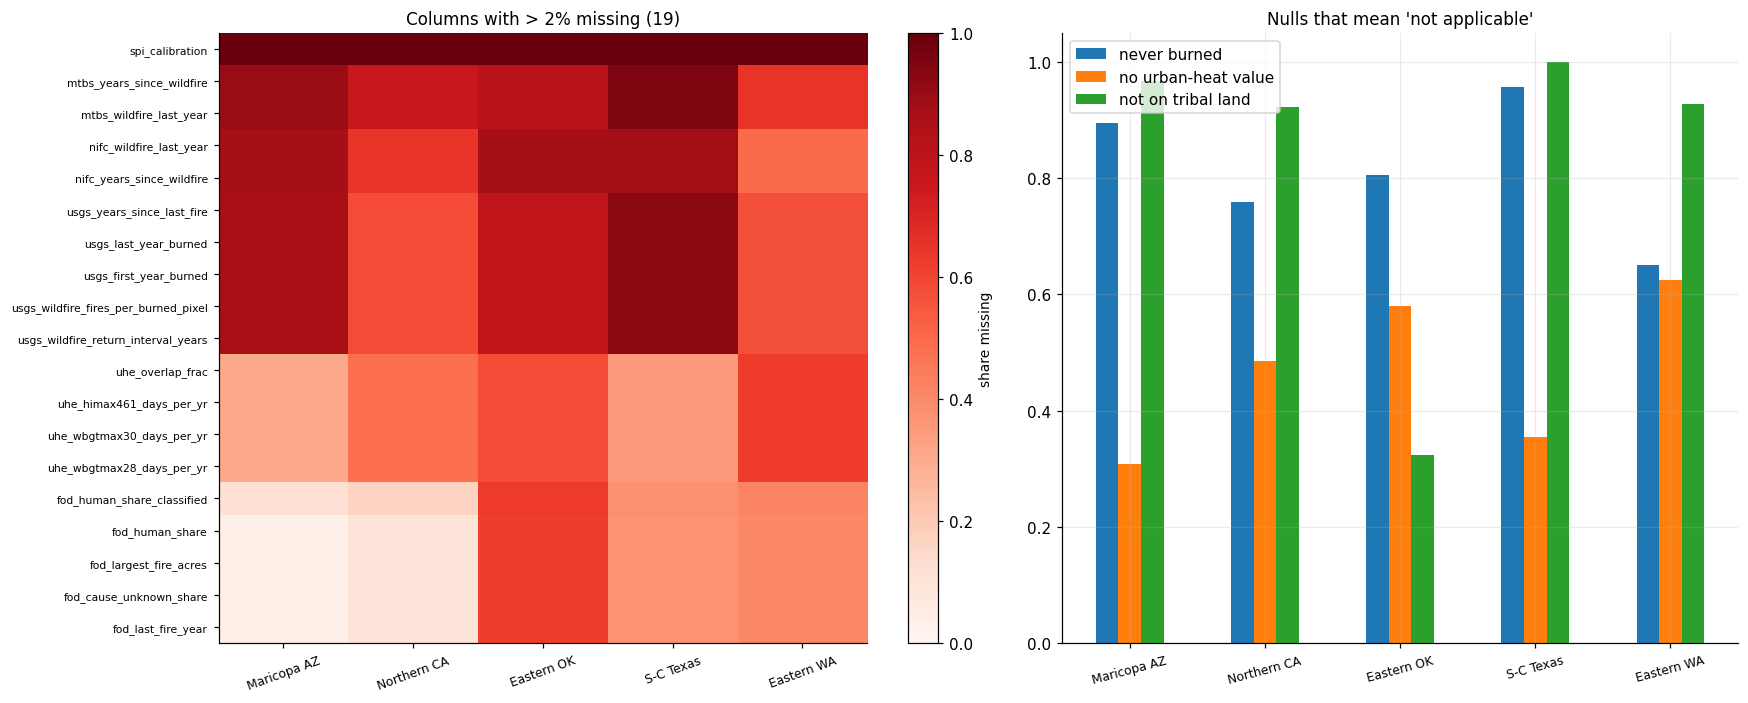

In [7]:
strata = pd.read_parquet(OUT / "scored_tracts_strata.parquet").columns
num = df[[c for c in df.columns if c in strata and df[c].dtype != object]]
miss = num.isna().groupby(df.region).mean().T.reindex(columns=REG); miss = miss[miss.max(axis=1) > .02].sort_values("maricopa-az", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})
im = ax[0].imshow(miss.values, aspect="auto", cmap="Reds", vmin=0, vmax=1); ax[0].grid(False)
ax[0].set_xticks(range(5)); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=8, rotation=20); ax[0].set_yticks(range(len(miss))); ax[0].set_yticklabels(miss.index, fontsize=7)
plt.colorbar(im, ax=ax[0], label="share missing"); ax[0].set_title(f"Columns with > 2% missing ({len(miss)})")
s = pd.DataFrame({"never burned": 1 - df.groupby("region").mtbs_wildfire_ever.apply(lambda x: x.astype(float).mean()),
                  "no urban-heat value": df.groupby("region").uhe_wbgtmax28_days_per_yr.apply(lambda x: x.isna().mean()),
                  "not on tribal land": df.groupby("region").aiannh_name.apply(lambda x: x.isna().mean())}).reindex(REG)
s.plot.bar(ax=ax[1], rot=15); ax[1].set_xticklabels([NAME[r] for r in REG], fontsize=8); ax[1].set_title("Nulls that mean 'not applicable'"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Takeaway:** the large null blocks are structural (a tract that never burned has no fire year, a non-tribal tract has no tribal-area name). That is missing *by design*, not at random, so mean-imputing it would be wrong; keep an indicator instead.

## 7. How do the strata relate to each other?

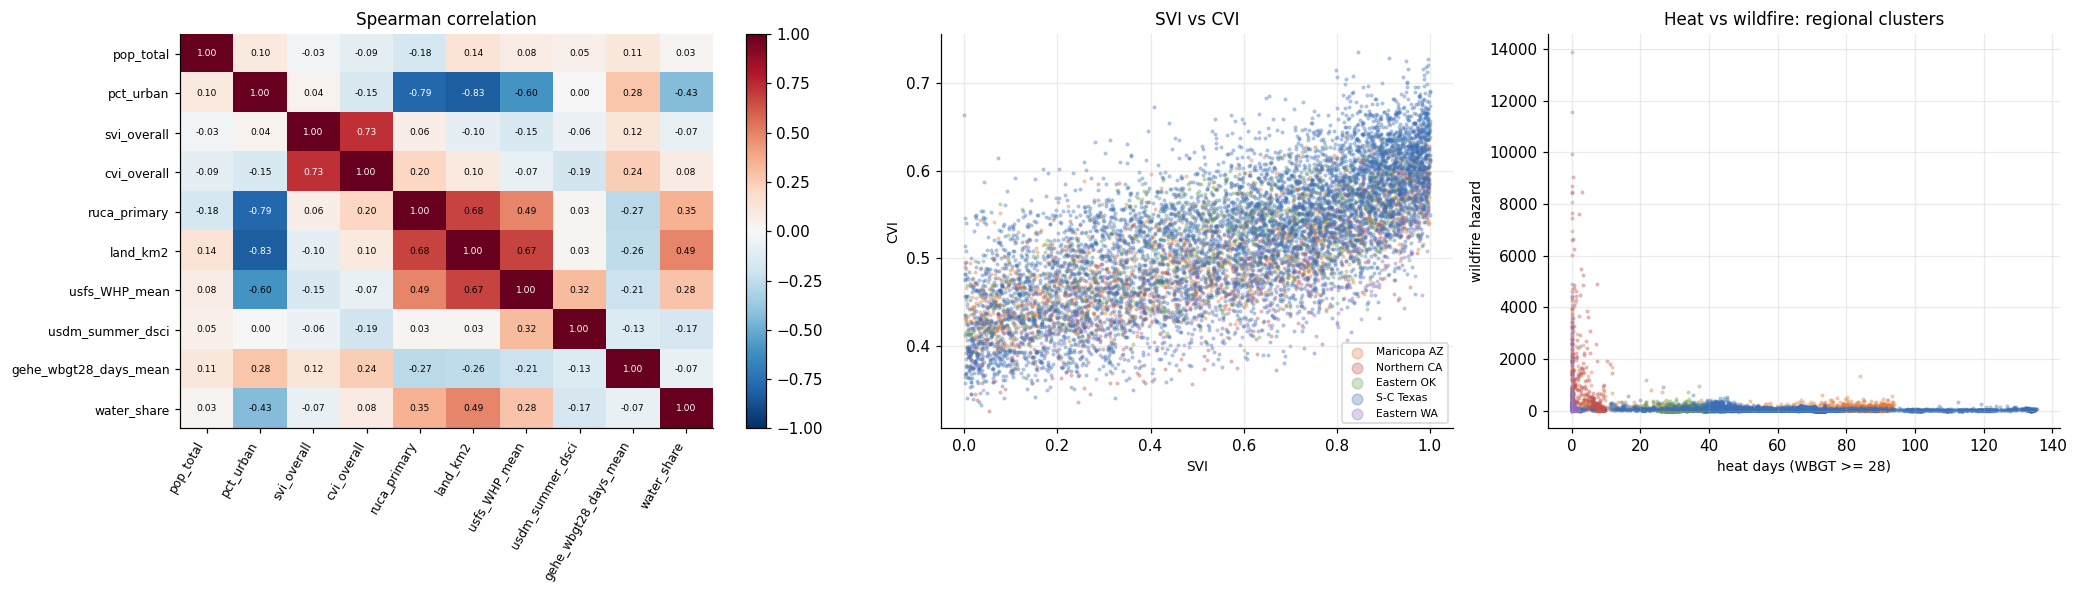

Spearman SVI-CVI: 0.73 | pct_urban-RUCA: -0.79


In [8]:
cols = ["pop_total", "pct_urban", "svi_overall", "cvi_overall", "ruca_primary", "land_km2", "usfs_WHP_mean", "usdm_summer_dsci", "gehe_wbgt28_days_mean", "water_share"]
cm = df[cols].corr(method="spearman")
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.3, 1, 1]})
plt.colorbar(heat(ax[0], cm, fs=6), ax=ax[0]); ax[0].set_title("Spearman correlation")
for r in REG:
    d = df[df.region == r]; ax[1].scatter(d.svi_overall, d.cvi_overall, s=3, alpha=.3, color=COL[r], label=NAME[r]); ax[2].scatter(d.gehe_wbgt28_days_mean, d.usfs_WHP_mean, s=3, alpha=.3, color=COL[r])
ax[1].set(xlabel="SVI", ylabel="CVI", title="SVI vs CVI"); ax[1].legend(markerscale=4, fontsize=7); ax[2].set(xlabel="heat days (WBGT >= 28)", ylabel="wildfire hazard", title="Heat vs wildfire: regional clusters")
plt.tight_layout(); plt.show()
print("Spearman SVI-CVI:", round(cm.loc["svi_overall", "cvi_overall"], 2), "| pct_urban-RUCA:", round(cm.loc["pct_urban", "ruca_primary"], 2))

**Takeaway:** SVI and CVI are related but not interchangeable, and the hazard variables form regional clusters (right panel), so a correlation across all tracts mixes between-region and within-region effects.